<a href="https://colab.research.google.com/github/jegedeolakunle21-art/ML-Enhanced-CFD-Surrogate-for-Thermal-System-Optimization/blob/main/CFD_ML_HEAT_EXCHANGER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA GENERATION COMPLETED
Rows: 3,000
Columns: 19
Dataset: /content/ml_cfd_thermal_project/synthetic_heat_exchanger_dataset.csv
Metadata: /content/ml_cfd_thermal_project/dataset_metadata.json

IMPORTANT: SYNTHETIC DATA, NOT CFD RESULTS.

Dataset preview:


,case_id,data_source,reynolds_number,prandtl_number,mass_flow_kg_s,inlet_temp_C,wall_heat_flux_W_m2,tube_diameter_m,tube_length_m,density_kg_m3,viscosity_Pa_s,conductivity_W_mK,specific_heat_J_kgK,pressure_drop_Pa,outlet_temp_C,nusselt_number,heat_transfer_coeff_W_m2K,heat_transfer_rate_W,friction_factor_Darcy
0,1,synthetic_correlation,79656.044370,4.331567,1.086048,33.104881,2831.295629,0.026584,1.910953,992.0,0.000653,0.63,4179.0,2620.365514,33.204442,344.636147,8167.217845,451.868718,0.018892
1,2,synthetic_correlation,49499.059578,4.331567,0.555502,23.690855,2091.352647,0.021882,1.237716,992.0,0.000653,0.63,4179.0,1306.732456,23.767507,235.539308,6781.386920,177.944087,0.021006
2,3,synthetic_correlation,87273.812792,4.331567,0.666789,27.334461,837.751237,0.014897,2.138347,992.0,0.000653,0.63,4179.0,19612.182763,27.364548,370.760105,15679.491021,83.838729,0.018523
3,4,synthetic_correlation,72763.122615,4.331567,0.929713,20.445758,4959.373937,0.024914,1.312858,992.0,0.000653,0.63,4179.0,1861.532829,20.576920,320.564112,8106.263282,509.599641,0.019269
4,5,synthetic_correlation,18475.961310,4.331567,0.110767,20.133203,1286.481770,0.011690,1.121917,992.0,0.000653,0.63,4179.0,1375.289230,20.247710,107.070905,5770.476888,53.004705,0.026689
5,6,synthetic_correlation,97806.011647,4.331567,1.278529,30.581798,1648.888137,0.025488,1.997336,992.0,0.000653,0.63,4179.0,4482.968684,30.631156,406.142349,10038.688774,263.714470,0.018077
6,7,synthetic_correlation,78502.573179,4.331567,0.877683,21.774404,1561.620931,0.021800,2.310747,992.0,0.000653,0.63,4179.0,5598.881987,21.841782,340.637888,9844.255909,247.131713,0.018952
7,8,synthetic_correlation,80745.787475,4.331567,0.505844,28.217124,4585.736330,0.012215,2.708295,992.0,0.000653,0.63,4179.0,39222.036218,28.442578,348.402880,17969.193626,476.593984,0.018836
8,9,synthetic_correlation,21530.226941,4.331567,0.127979,30.440112,3936.597767,0.011590,2.565671,992.0,0.000653,0.63,4179.0,4213.788911,31.127731,121.010965,6577.754610,367.755777,0.025666
9,10,synthetic_correlation,50534.734411,4.331567,0.648371,20.483519,2557.984097,0.025017,2.714481,992.0,0.000653,0.63,4179.0,1989.511458,20.684923,239.473702,6030.702338,545.713888,0.020907



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
case_id,3000.0,1500.5000,866.1697,1.0000,750.7500,1500.5000,2250.2500,3000.0000
reynolds_number,3000.0,54956.4065,26113.1773,10046.6870,32006.9440,54635.2219,78047.1774,99978.8803
prandtl_number,3000.0,4.3316,0.0000,4.3316,4.3316,4.3316,4.3316,4.3316
mass_flow_kg_s,3000.0,0.5603,0.3235,0.0558,0.2914,0.5089,0.7766,1.5269
inlet_temp_C,3000.0,27.5004,4.3209,20.0002,23.6856,27.6021,31.1623,34.9920
wall_heat_flux_W_m2,3000.0,2759.3958,1285.4886,500.5621,1644.4352,2775.1618,3862.9705,4999.7627
tube_diameter_m,3000.0,0.0198,0.0057,0.0100,0.0149,0.0197,0.0247,0.0300
tube_length_m,3000.0,2.0030,0.5755,1.0008,1.5100,2.0105,2.4886,3.0000
density_kg_m3,3000.0,992.0000,0.0000,992.0000,992.0000,992.0000,992.0000,992.0000
viscosity_Pa_s,3000.0,0.0007,0.0000,0.0007,0.0007,0.0007,0.0007,0.0007


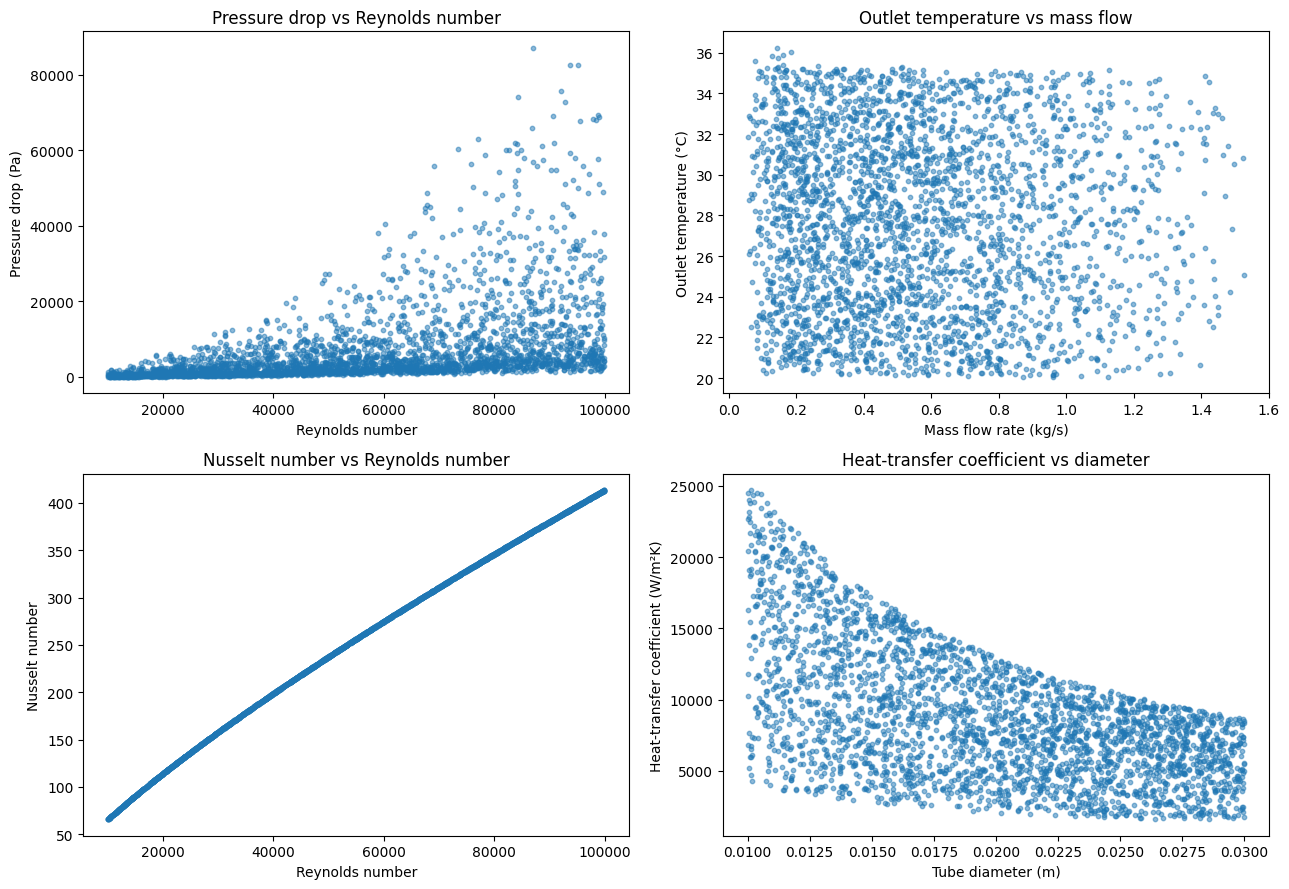

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ================================================================
# PROJECT: ML-Enhanced CFD Surrogate for Thermal-System Optimization
# PHASE 2: SYNTHETIC DATA GENERATION
#
# IMPORTANT:
# These are correlation-derived synthetic results, NOT ANSYS CFD data.
# The dataset is for pipeline development and preliminary ML testing.
# ================================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------------------
# 1. Reproducibility and settings
# -------------------------------
SEED = 42
N_CASES = 3000

rng = np.random.default_rng(SEED)
OUTPUT_DIR = Path("/content/ml_cfd_thermal_project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------
# 2. Fixed water properties
# Approximate values at 40 degrees C.
# These remain fixed in this prototype.
# -------------------------------
RHO = 992.0          # kg/m^3
MU = 0.653e-3        # Pa.s
K_FLUID = 0.630      # W/(m.K)
CP = 4179.0          # J/(kg.K)
PR = MU * CP / K_FLUID

# -------------------------------
# 3. Sample operating conditions
# -------------------------------
Re = rng.uniform(10_000, 100_000, N_CASES)
D = rng.uniform(0.010, 0.030, N_CASES)       # m
L = rng.uniform(1.0, 3.0, N_CASES)           # m
Tin = rng.uniform(20.0, 35.0, N_CASES)       # degrees C
q_wall = rng.uniform(500.0, 5000.0, N_CASES) # W/m^2

# Calculate mass flow from the Reynolds-number definition.
# Re = 4 * mass_flow / (pi * D * viscosity)
mass_flow = Re * np.pi * D * MU / 4.0

# Mean velocity from mass conservation.
area_flow = np.pi * D**2 / 4.0
velocity = mass_flow / (RHO * area_flow)

# -------------------------------
# 4. Heat transfer calculations
# Dittus-Boelter correlation:
# Nu = 0.023 * Re^0.8 * Pr^0.4
#
# Assumes heating of the fluid, fully developed turbulent
# flow, and correlation applicability.
# -------------------------------
Nu = 0.023 * Re**0.8 * PR**0.4

h = Nu * K_FLUID / D  # W/(m^2.K)

# Heated wall area for a circular tube.
wall_area = np.pi * D * L

# Prescribed uniform wall heat flux.
Q = q_wall * wall_area  # W

# Energy balance, neglecting heat loss.
Tout = Tin + Q / (mass_flow * CP)

# -------------------------------
# 5. Pressure-drop calculation
# Darcy friction factor for a smooth tube:
# f = (0.79 * ln(Re) - 1.64)^(-2)
#
# Darcy-Weisbach pressure drop:
# delta_P = f * (L/D) * rho * velocity^2 / 2
# -------------------------------
f_darcy = 1.0 / (0.79 * np.log(Re) - 1.64)**2

delta_P = (
    f_darcy
    * (L / D)
    * (RHO * velocity**2 / 2.0)
)

# -------------------------------
# 6. Assemble dataset
# -------------------------------
df = pd.DataFrame({
    "case_id": np.arange(1, N_CASES + 1),
    "data_source": "synthetic_correlation",
    "reynolds_number": Re,
    "prandtl_number": np.full(N_CASES, PR),
    "mass_flow_kg_s": mass_flow,
    "inlet_temp_C": Tin,
    "wall_heat_flux_W_m2": q_wall,
    "tube_diameter_m": D,
    "tube_length_m": L,
    "density_kg_m3": np.full(N_CASES, RHO),
    "viscosity_Pa_s": np.full(N_CASES, MU),
    "conductivity_W_mK": np.full(N_CASES, K_FLUID),
    "specific_heat_J_kgK": np.full(N_CASES, CP),
    "pressure_drop_Pa": delta_P,
    "outlet_temp_C": Tout,
    "nusselt_number": Nu,
    "heat_transfer_coeff_W_m2K": h,
    "heat_transfer_rate_W": Q,
    "friction_factor_Darcy": f_darcy,
})

# -------------------------------
# 7. Data-quality checks
# -------------------------------
assert df.isna().sum().sum() == 0, "Missing values found"
assert df.select_dtypes(include=np.number).notna().all().all()
assert (df["mass_flow_kg_s"] > 0).all()
assert (df["pressure_drop_Pa"] > 0).all()
assert (df["nusselt_number"] > 0).all()
assert (df["heat_transfer_coeff_W_m2K"] > 0).all()
assert (df["outlet_temp_C"] > df["inlet_temp_C"]).all()
assert (df["reynolds_number"] >= 10_000).all()
assert (df["tube_length_m"] / df["tube_diameter_m"] >= 10).all()

# Independently verify the Reynolds-number definition.
Re_check = (
    4.0 * df["mass_flow_kg_s"]
    / (np.pi * df["tube_diameter_m"] * MU)
)
assert np.allclose(Re_check, df["reynolds_number"])

# Independently verify the energy balance.
Q_check = (
    df["mass_flow_kg_s"] * CP
    * (df["outlet_temp_C"] - df["inlet_temp_C"])
)
assert np.allclose(Q_check, df["heat_transfer_rate_W"])

# -------------------------------
# 8. Export dataset and metadata
# -------------------------------
csv_path = OUTPUT_DIR / "synthetic_heat_exchanger_dataset.csv"
json_path = OUTPUT_DIR / "dataset_metadata.json"

df.to_csv(csv_path, index=False)

metadata = {
    "project": "ML-Enhanced CFD Surrogate for Thermal-System Optimization",
    "phase": 2,
    "dataset_type": "Synthetic, correlation-derived",
    "is_genuine_cfd_data": False,
    "number_of_cases": N_CASES,
    "random_seed": SEED,
    "fluid": "Water, fixed approximate properties at 40 C",
    "geometry": "Straight circular tube",
    "flow_assumption": "Steady, single-phase, turbulent internal flow",
    "thermal_boundary_condition": "Uniform prescribed wall heat flux",
    "heat_transfer_correlation": "Dittus-Boelter, n=0.4",
    "friction_factor_correlation": "Smooth-tube approximation",
    "pressure_drop_model": "Darcy-Weisbach",
    "energy_model": "Q = q_wall * pi * D * L",
    "temperature_model": "Tout = Tin + Q / (mass_flow * cp)",
    "limitations": [
        "Not generated by ANSYS Fluent or CFX",
        "Not experimentally validated",
        "Fluid properties are fixed",
        "Simplified smooth-tube correlations",
        "No transition-flow cases",
        "No shell-side flow or complex heat exchanger geometry",
        "No thermal performance factor target is defined"
    ],
    "primary_targets": [
        "pressure_drop_Pa",
        "outlet_temp_C",
        "nusselt_number",
        "heat_transfer_coeff_W_m2K"
    ]
}

with open(json_path, "w") as f:
    json.dump(metadata, f, indent=2)

# -------------------------------
# 9. Summary and previews
# -------------------------------
print("DATA GENERATION COMPLETED")
print("=" * 60)
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Dataset: {csv_path}")
print(f"Metadata: {json_path}")
print("\nIMPORTANT: SYNTHETIC DATA, NOT CFD RESULTS.")

print("\nDataset preview:")
display(df.head(10))

print("\nStatistical summary:")
display(df.describe().T.round(4))

# -------------------------------
# 10. Exploratory plots
# -------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].scatter(
    df["reynolds_number"], df["pressure_drop_Pa"],
    s=10, alpha=0.5
)
axes[0, 0].set_xlabel("Reynolds number")
axes[0, 0].set_ylabel("Pressure drop (Pa)")
axes[0, 0].set_title("Pressure drop vs Reynolds number")

axes[0, 1].scatter(
    df["mass_flow_kg_s"], df["outlet_temp_C"],
    s=10, alpha=0.5
)
axes[0, 1].set_xlabel("Mass flow rate (kg/s)")
axes[0, 1].set_ylabel("Outlet temperature (°C)")
axes[0, 1].set_title("Outlet temperature vs mass flow")

axes[1, 0].scatter(
    df["reynolds_number"], df["nusselt_number"],
    s=10, alpha=0.5
)
axes[1, 0].set_xlabel("Reynolds number")
axes[1, 0].set_ylabel("Nusselt number")
axes[1, 0].set_title("Nusselt number vs Reynolds number")

axes[1, 1].scatter(
    df["tube_diameter_m"], df["heat_transfer_coeff_W_m2K"],
    s=10, alpha=0.5
)
axes[1, 1].set_xlabel("Tube diameter (m)")
axes[1, 1].set_ylabel("Heat-transfer coefficient (W/m²K)")
axes[1, 1].set_title("Heat-transfer coefficient vs diameter")

plt.tight_layout()
plt.show()

# -------------------------------
# 11. Download files in Colab
# -------------------------------
from google.colab import files

files.download(str(csv_path))
files.download(str(json_path))


In [3]:
FEATURES = [
    "mass_flow_kg_s",
    "inlet_temp_C",
    "wall_heat_flux_W_m2",
    "tube_diameter_m",
    "tube_length_m",
]

TARGETS = [
    "pressure_drop_Pa",
    "outlet_temp_C",
    "nusselt_number",
    "heat_transfer_coeff_W_m2K",
]

Dataset rows: 3000
Features: ['mass_flow_kg_s', 'inlet_temp_C', 'wall_heat_flux_W_m2', 'tube_diameter_m', 'tube_length_m']
Targets: ['pressure_drop_Pa', 'outlet_temp_C', 'nusselt_number', 'heat_transfer_coeff_W_m2K']
Data source: synthetic_correlation

Training cases: 2400
Held-out test cases: 600

Cross-validation: pressure_drop_Pa
  Linear Regression: CV RMSE = 7798.98 +/- 747
  Random Forest: CV RMSE = 1653.4 +/- 345
  XGBoost: CV RMSE = 1361.57 +/- 201
  Artificial Neural Network: CV RMSE = 1054.87 +/- 155

Cross-validation: outlet_temp_C
  Linear Regression: CV RMSE = 0.12632 +/- 0.00503
  Random Forest: CV RMSE = 0.154108 +/- 0.00676
  XGBoost: CV RMSE = 0.162697 +/- 0.00869
  Artificial Neural Network: CV RMSE = 0.232529 +/- 0.0269

Cross-validation: nusselt_number
  Linear Regression: CV RMSE = 27.9716 +/- 0.491
  Random Forest: CV RMSE = 3.64158 +/- 0.455
  XGBoost: CV RMSE = 4.60836 +/- 0.321
  Artificial Neural Network: CV RMSE = 7.17435 +/- 1.16

Cross-validation: heat_tran

,target,model,test_MAE,test_RMSE,test_R2,inference_batch_ms,inference_ms_per_case,cv_RMSE_mean,selected_by_cv
0,heat_transfer_coeff_W_m2K,Random Forest,127.959270,193.862842,0.998072,77.369553,0.604450,226.174347,True
1,heat_transfer_coeff_W_m2K,XGBoost,165.914956,237.676593,0.997102,1.732315,0.013534,286.192135,False
2,heat_transfer_coeff_W_m2K,Artificial Neural Network,256.410989,384.547715,0.992413,1.918854,0.014991,486.535791,False
3,heat_transfer_coeff_W_m2K,Linear Regression,1611.445396,2200.397931,0.751596,1.713394,0.013386,2153.349775,False
4,nusselt_number,Random Forest,2.168076,3.051464,0.999044,71.369186,0.557572,3.641584,True
5,nusselt_number,XGBoost,3.151577,4.222359,0.998170,4.264955,0.033320,4.608364,False
6,nusselt_number,Artificial Neural Network,5.080313,6.855828,0.995176,1.818547,0.014207,7.174351,False
7,nusselt_number,Linear Regression,21.686355,29.159921,0.912730,1.715926,0.013406,27.971620,False
8,outlet_temp_C,Linear Regression,0.085229,0.129271,0.999112,1.854924,0.014492,0.126320,True
9,outlet_temp_C,Random Forest,0.084629,0.136260,0.999013,74.128384,0.579128,0.154108,False



BEST MODEL PER TARGET (selected on CV, not test score)


,target,model,test_MAE,test_RMSE,test_R2,inference_ms_per_case
0,pressure_drop_Pa,Artificial Neural Network,615.856891,1216.230515,0.985443,0.014686
1,outlet_temp_C,Linear Regression,0.085229,0.129271,0.999112,0.014492
2,nusselt_number,Random Forest,2.168076,3.051464,0.999044,0.557572
3,heat_transfer_coeff_W_m2K,Random Forest,127.959270,193.862842,0.998072,0.604450


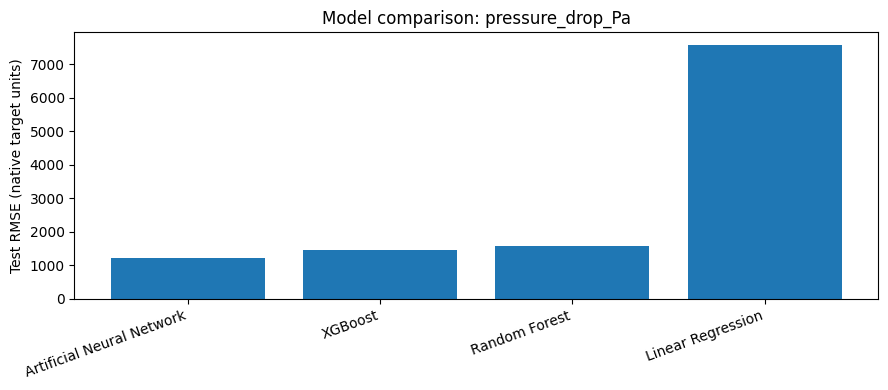

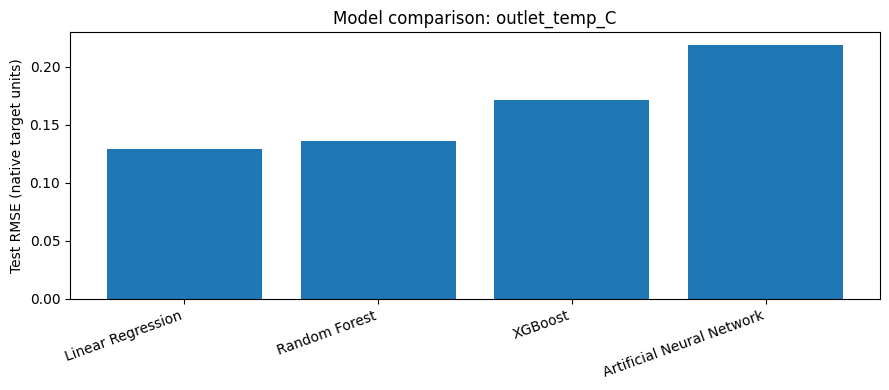

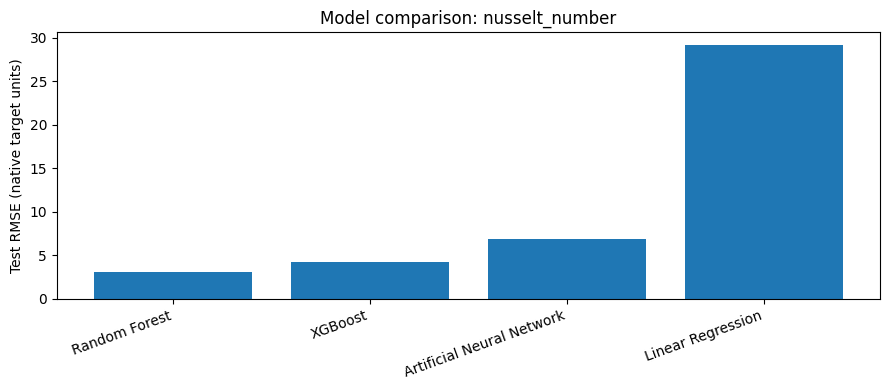

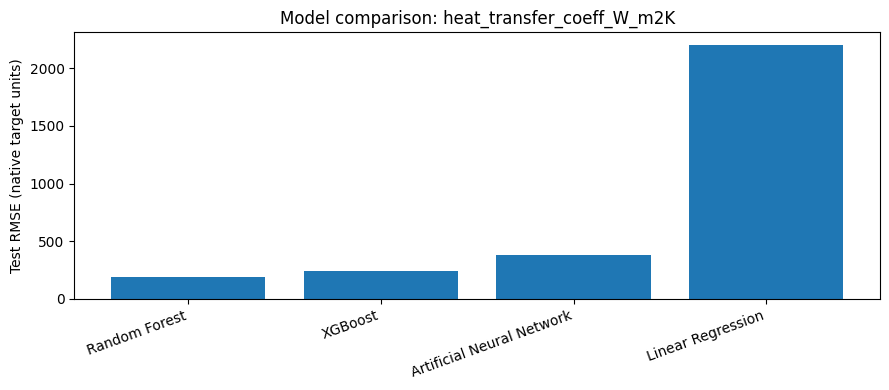

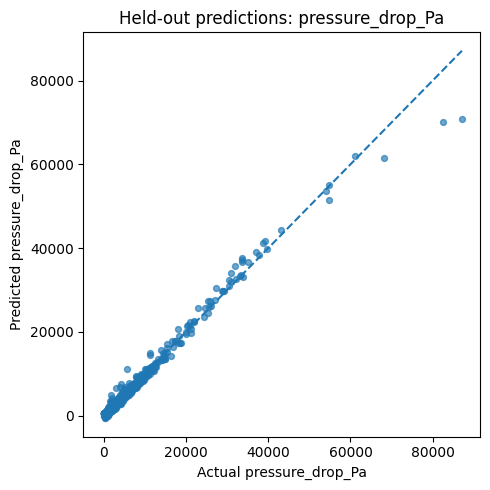

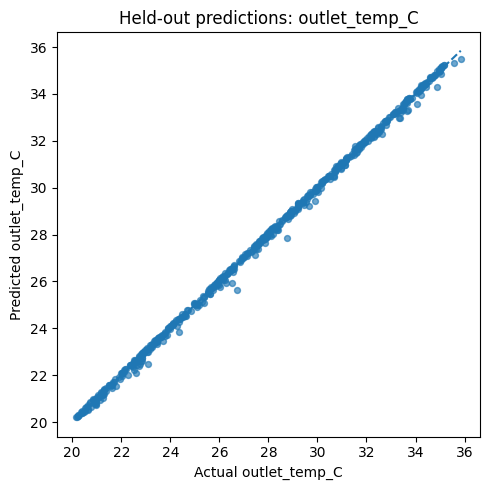

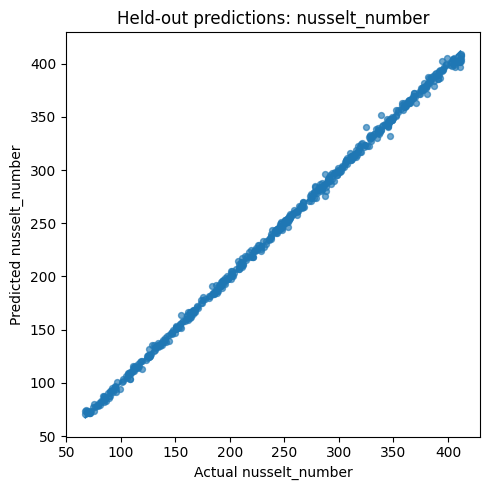

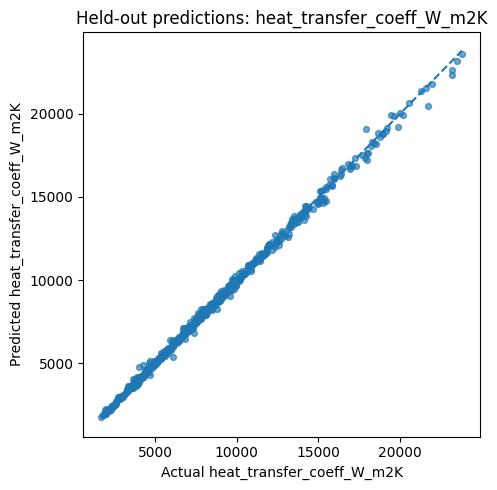


FILES SAVED
Models: /content/ml_cfd_thermal_project/models
Results: /content/ml_cfd_thermal_project/phase3_results
CV results: cross_validation_results.csv
Metrics: test_metrics_all_models.csv
Predictions: best_model_test_predictions.csv
Selected models: best_surrogate_models.joblib

Reminder: metrics are for synthetic data, not ANSYS validation.


In [4]:

# ================================================================
# PHASE 3: ML SURROGATE MODEL TRAINING AND EVALUATION
# Dataset: Synthetic heat-exchanger correlation data
# NOT genuine ANSYS CFD or experimental data
# ================================================================

# 1. Install dependencies
%pip -q install xgboost joblib

import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
ROOT = Path("/content/ml_cfd_thermal_project")
DATA_PATH = ROOT / "synthetic_heat_exchanger_dataset.csv"
MODEL_DIR = ROOT / "models"
RESULT_DIR = ROOT / "phase3_results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load the dataset
if not DATA_PATH.exists():
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError(
            "Upload synthetic_heat_exchanger_dataset.csv from Phase 2."
        )
    DATA_PATH = Path("/content") / csv_files[0]

df = pd.read_csv(DATA_PATH)

FEATURES = [
    "mass_flow_kg_s",
    "inlet_temp_C",
    "wall_heat_flux_W_m2",
    "tube_diameter_m",
    "tube_length_m",
]

TARGETS = [
    "pressure_drop_Pa",
    "outlet_temp_C",
    "nusselt_number",
    "heat_transfer_coeff_W_m2K",
]

required = FEATURES + TARGETS
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

if not np.isfinite(df[required].to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite values found in model columns.")

if len(df) < 100:
    raise ValueError("Dataset is unexpectedly small. Check the CSV.")

X = df[FEATURES].copy()
Y = df[TARGETS].copy()

print("Dataset rows:", len(df))
print("Features:", FEATURES)
print("Targets:", TARGETS)
print("Data source:", df["data_source"].iloc[0]
      if "data_source" in df.columns else "Verify dataset provenance")

# 3. Split once: identical rows for all models and targets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=SEED
)

print(f"\nTraining cases: {len(X_train)}")
print(f"Held-out test cases: {len(X_test)}")

# 4. Define the four algorithms
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0
    ),

    "Artificial Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=1500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=30,
            random_state=SEED
        ))
    ])
}

# 5. Five-fold cross-validation on TRAINING data only
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_records = []
for target in TARGETS:
    print(f"\nCross-validation: {target}")

    for model_name, estimator in models.items():
        scores = cross_val_score(
            clone(estimator),
            X_train,
            Y_train[target],
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=1
        )

        cv_rmse = -scores

        cv_records.append({
            "target": target,
            "model": model_name,
            "cv_rmse_mean": cv_rmse.mean(),
            "cv_rmse_std": cv_rmse.std(ddof=1)
        })

        print(
            f"  {model_name}: "
            f"CV RMSE = {cv_rmse.mean():.6g} "
            f"+/- {cv_rmse.std(ddof=1):.3g}"
        )

cv_results = pd.DataFrame(cv_records)
cv_results.to_csv(RESULT_DIR / "cross_validation_results.csv", index=False)

# 6. Train final models, test once, and measure inference time
metric_records = []
predictions = pd.DataFrame(index=X_test.index)
best_models = {}
model_registry = {}

for target in TARGETS:
    print(f"\nFinal training: {target}")

    y_train = Y_train[target]
    y_test = Y_test[target]

    # Select using training cross-validation only.
    target_cv = cv_results[cv_results["target"] == target]
    best_name = target_cv.sort_values("cv_rmse_mean").iloc[0]["model"]

    for model_name, estimator in models.items():
        fitted = clone(estimator)
        fitted.fit(X_train, y_train)

        pred = np.asarray(fitted.predict(X_test)).ravel()

        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))
        r2 = r2_score(y_test, pred)

        # Warm up before timing. This is a batch prediction benchmark.
        batch = X_test.iloc[:min(128, len(X_test))]
        fitted.predict(batch)

        repeats = 30
        start = time.perf_counter()
        for _ in range(repeats):
            fitted.predict(batch)
        elapsed = time.perf_counter() - start

        batch_ms = 1000 * elapsed / repeats
        per_case_ms = batch_ms / len(batch)

        metric_records.append({
            "target": target,
            "model": model_name,
            "test_MAE": mae,
            "test_RMSE": rmse,
            "test_R2": r2,
            "inference_batch_ms": batch_ms,
            "inference_ms_per_case": per_case_ms,
            "cv_RMSE_mean": float(
                target_cv.loc[
                    target_cv["model"] == model_name,
                    "cv_rmse_mean"
                ].iloc[0]
            ),
            "selected_by_cv": model_name == best_name
        })

        # Save every fitted model for comparison and reproducibility.
        safe_target = target.replace("/", "_")
        safe_model = model_name.lower().replace(" ", "_")
        model_path = MODEL_DIR / f"{safe_target}__{safe_model}.joblib"
        joblib.dump(fitted, model_path)

        model_registry[(target, model_name)] = fitted

        if model_name == best_name:
            best_models[target] = fitted
            predictions[f"{target}_actual"] = y_test
            predictions[f"{target}_predicted"] = pred

        print(
            f"  {model_name}: MAE={mae:.6g}, "
            f"RMSE={rmse:.6g}, R2={r2:.6f}"
        )

metrics = pd.DataFrame(metric_records)
metrics.to_csv(RESULT_DIR / "test_metrics_all_models.csv", index=False)

predictions.to_csv(
    RESULT_DIR / "best_model_test_predictions.csv", index=False
)

# 7. Save the CV-selected model for each target.
# Each model uses the same five input features.
best_bundle = {
    "models": best_models,
    "features": FEATURES,
    "targets": TARGETS,
    "dataset_type": "synthetic_correlation",
    "genuine_cfd_validated": False,
    "random_seed": SEED
}

joblib.dump(best_bundle, MODEL_DIR / "best_surrogate_models.joblib")

with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump({
        "dataset_type": "Synthetic correlation-derived dataset",
        "genuine_cfd_validated": False,
        "features": FEATURES,
        "targets": TARGETS,
        "selection_method": "Lowest mean 5-fold CV RMSE per target",
        "test_fraction": 0.20,
        "random_seed": SEED
    }, f, indent=2)

# 8. Show comparison tables
print("\nTEST-SET MODEL COMPARISON")
display(
    metrics.sort_values(["target", "test_RMSE"])
    .round(6)
    .reset_index(drop=True)
)

print("\nBEST MODEL PER TARGET (selected on CV, not test score)")
display(
    metrics[metrics["selected_by_cv"]][[
        "target", "model", "test_MAE",
        "test_RMSE", "test_R2", "inference_ms_per_case"
    ]].round(6).reset_index(drop=True)
)

# 9. Plot test RMSE by target and model
for target in TARGETS:
    subset = metrics[metrics["target"] == target].sort_values("test_RMSE")

    plt.figure(figsize=(9, 4))
    plt.bar(subset["model"], subset["test_RMSE"])
    plt.ylabel("Test RMSE (native target units)")
    plt.title(f"Model comparison: {target}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

# 10. Plot actual vs predicted for CV-selected models
for target in TARGETS:
    actual = predictions[f"{target}_actual"]
    predicted = predictions[f"{target}_predicted"]

    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())

    plt.figure(figsize=(5, 5))
    plt.scatter(actual, predicted, alpha=0.65, s=18)
    plt.plot([low, high], [low, high], linestyle="--")
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Held-out predictions: {target}")
    plt.tight_layout()
    plt.show()

# 11. Export reproducibility information
print("\nFILES SAVED")
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)
print("CV results: cross_validation_results.csv")
print("Metrics: test_metrics_all_models.csv")
print("Predictions: best_model_test_predictions.csv")
print("Selected models: best_surrogate_models.joblib")
print("\nReminder: metrics are for synthetic data, not ANSYS validation.")


In [5]:

# ================================================================
# PHASE 4: CONSTRAINED HEAT-EXCHANGER OPTIMIZATION
# Uses Phase 3 models trained on SYNTHETIC correlation-derived data.
# NOT a validated CFD optimization.
# ================================================================

%pip -q install scipy joblib

import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import differential_evolution, NonlinearConstraint

ROOT = Path("/content/ml_cfd_thermal_project")
MODEL_PATH = ROOT / "models" / "best_surrogate_models.joblib"
OUTPUT_DIR = ROOT / "phase4_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "Selected model bundle not found. Run Phase 3 first."
    )

bundle = joblib.load(MODEL_PATH)

if bundle.get("genuine_cfd_validated", True):
    raise ValueError("Unexpected model provenance; verify the metadata.")

models = bundle["models"]
features = bundle["features"]

required_targets = [
    "pressure_drop_Pa",
    "outlet_temp_C",
    "nusselt_number",
    "heat_transfer_coeff_W_m2K"
]
missing = [t for t in required_targets if t not in models]
if missing:
    raise ValueError(f"Missing trained target models: {missing}")

# Fixed fluid properties used in Phase 2.
RHO = 992.0
MU = 0.653e-3
K_FLUID = 0.630
CP = 4179.0

# Illustrative limits: adapt to a real engineering requirement.
MAX_PRESSURE_DROP_PA = 60_000.0
MAX_OUTLET_TEMP_C = 60.0

# Decision variables:
# [Re, D (m), L (m), Tin (C), wall heat flux (W/m2)]
bounds = [
    (10_000.0, 100_000.0),
    (0.010, 0.030),
    (1.0, 3.0),
    (20.0, 35.0),
    (500.0, 5_000.0)
]

def make_features(x):
    Re, D, L, Tin, q_wall = x

    # Enforce the Reynolds-number/mass-flow relationship.
    mass_flow = Re * np.pi * D * MU / 4.0

    return pd.DataFrame([{
        "mass_flow_kg_s": mass_flow,
        "inlet_temp_C": Tin,
        "wall_heat_flux_W_m2": q_wall,
        "tube_diameter_m": D,
        "tube_length_m": L
    }], columns=features)

def predict_design(x):
    row = make_features(x)

    result = {
        name: float(np.asarray(model.predict(row)).ravel()[0])
        for name, model in models.items()
    }

    Re, D, L, Tin, q_wall = x
    Q = q_wall * np.pi * D * L

    result.update({
        "reynolds_number": Re,
        "mass_flow_kg_s": float(row["mass_flow_kg_s"].iloc[0]),
        "tube_diameter_m": D,
        "tube_length_m": L,
        "inlet_temp_C": Tin,
        "wall_heat_flux_W_m2": q_wall,
        "heat_transfer_rate_W": Q
    })
    return result

def constraint_values(x):
    result = predict_design(x)

    # Both values must be >= 0.
    return np.array([
        MAX_PRESSURE_DROP_PA - result["pressure_drop_Pa"],
        MAX_OUTLET_TEMP_C - result["outlet_temp_C"]
    ])

constraints = NonlinearConstraint(
    constraint_values,
    lb=np.array([0.0, 0.0]),
    ub=np.array([np.inf, np.inf])
)

def objective(x):
    # Maximize heat-transfer rate by minimizing its negative.
    return -predict_design(x)["heat_transfer_rate_W"]

print("Starting constrained optimization...")
print("Objective: maximize heat-transfer rate")
print(f"Pressure-drop limit: {MAX_PRESSURE_DROP_PA:,.0f} Pa")
print(f"Outlet-temperature limit: {MAX_OUTLET_TEMP_C:.1f} °C")

result = differential_evolution(
    objective,
    bounds=bounds,
    constraints=(constraints,),
    seed=42,
    maxiter=150,
    popsize=12,
    tol=1e-6,
    polish=False,
    workers=1
)

if not result.success:
    print("\nOptimizer message:", result.message)

if not result.success or not np.all(constraint_values(result.x) >= -1e-5):
    raise RuntimeError(
        "No verified feasible solution was returned. "
        "Check the constraints, model predictions and search settings."
    )

best = predict_design(result.x)

# Save the selected candidate and settings.
best["pressure_drop_limit_Pa"] = MAX_PRESSURE_DROP_PA
best["outlet_temp_limit_C"] = MAX_OUTLET_TEMP_C
best["optimizer"] = "Differential Evolution"
best["data_source"] = "Synthetic correlation-derived surrogate"
best["genuine_cfd_validated"] = False

best_df = pd.DataFrame([best])
best_df.to_csv(OUTPUT_DIR / "optimal_design_candidate.csv", index=False)

with open(OUTPUT_DIR / "optimization_metadata.json", "w") as f:
    json.dump({
        "objective": "Maximize q_wall * pi * diameter * length",
        "constraints": {
            "pressure_drop_max_Pa": MAX_PRESSURE_DROP_PA,
            "outlet_temperature_max_C": MAX_OUTLET_TEMP_C
        },
        "decision_variables": [
            "Reynolds number", "tube diameter",
            "tube length", "inlet temperature", "wall heat flux"
        ],
        "data_source": "Synthetic correlation-derived data",
        "genuine_cfd_validated": False,
        "optimizer_success": bool(result.success),
        "optimizer_message": str(result.message)
    }, f, indent=2)

print("\nOPTIMIZED CANDIDATE")
display(best_df.T.rename(columns={0: "value"}))

print("\nSaved results to:", OUTPUT_DIR)
print("Remember: this is a surrogate-based synthetic-data result.")


Starting constrained optimization...
Objective: maximize heat-transfer rate
Pressure-drop limit: 60,000 Pa
Outlet-temperature limit: 60.0 °C

OPTIMIZED CANDIDATE


,value
pressure_drop_Pa,428.057908
outlet_temp_C,27.48917
nusselt_number,143.247761
heat_transfer_coeff_W_m2K,3063.212429
reynolds_number,24535.873508
mass_flow_kg_s,0.377508
tube_diameter_m,0.03
tube_length_m,3.0
inlet_temp_C,26.802425
wall_heat_flux_W_m2,4999.99975



Saved results to: /content/ml_cfd_thermal_project/phase4_results
Remember: this is a surrogate-based synthetic-data result.


In [10]:
import pandas as pd

path = (
    "/content/ml_cfd_thermal_project/"
    "phase4_results/optimal_design_candidate.csv"
)

display(pd.read_csv(path).T)

,0
pressure_drop_Pa,428.057908
outlet_temp_C,27.48917
nusselt_number,143.247761
heat_transfer_coeff_W_m2K,3063.212429
reynolds_number,24535.873508
mass_flow_kg_s,0.377508
tube_diameter_m,0.03
tube_length_m,3.0
inlet_temp_C,26.802425
wall_heat_flux_W_m2,4999.99975


In [14]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="ML-Enhanced Heat Exchanger",
    page_icon="🌡️",
    layout="wide"
)

st.title("ML-Enhanced CFD Surrogate")
st.subheader("Heat Exchanger Prediction and Optimization")
st.write(
    "Predict thermal-hydraulic performance using trained "
    "machine-learning surrogate models."
)

MODEL_PATH = Path("/content/ml_cfd_thermal_project/models/best_surrogate_models.joblib")

FEATURES = [
    "mass_flow_kg_s",
    "inlet_temp_C",
    "wall_heat_flux_W_m2",
    "tube_diameter_m",
    "tube_length_m",
]

TARGETS = {
    "pressure_drop_Pa": "Predicted pressure drop (Pa)",
    "outlet_temp_C": "Predicted outlet temperature (°C)",
    "nusselt_number": "Predicted Nusselt number",
    "heat_transfer_coeff_W_m2K":
        "Predicted heat-transfer coefficient (W/m²·K)",
}

@st.cache_resource
def load_models():
    return joblib.load(MODEL_PATH)

if not MODEL_PATH.exists():
    st.error(f"Model file not found: {MODEL_PATH}")
    st.info("Upload the trained model to the models/ folder in GitHub.")
    st.stop()

models = load_models()

st.markdown("### Enter operating conditions")

col1, col2 = st.columns(2)

with col1:
    mass_flow = st.number_input(
        "Mass flow rate (kg/s)",
        min_value=0.001,
        value=0.10,
        step=0.01,
        format="%.4f"
    )
    inlet_temp = st.number_input(
        "Inlet temperature (°C)",
        min_value=0.0,
        max_value=100.0,
        value=30.0
    )
    wall_heat_flux = st.number_input(
        "Wall heat flux (W/m²)",
        min_value=1.0,
        value=2500.0
    )

with col2:
    diameter = st.number_input(
        "Tube diameter (m)",
        min_value=0.010,
        max_value=0.030,
        value=0.020,
        format="%.4f"
    )
    length = st.number_input(
        "Tube length (m)",
        min_value=1.0,
        max_value=3.0,
        value=2.0
    )

if st.button("Predict performance", type="primary"):
    if not isinstance(models, dict):
        st.error(
            "The model file is not a dictionary of target estimators. "
            "Inspect its structure and adapt the loading code."
        )
        st.stop()

    X = pd.DataFrame([{
        "mass_flow_kg_s": mass_flow,
        "inlet_temp_C": inlet_temp,
        "wall_heat_flux_W_m2": wall_heat_flux,
        "tube_diameter_m": diameter,
        "tube_length_m": length,
    }], columns=FEATURES)

    st.markdown("### Prediction results")
    results = {}

    for target, label in TARGETS.items():
        if target not in models:
            st.warning(f"Model not found for target: {target}")
            continue

        estimator = models[target]

        try:
            prediction = float(estimator.predict(X)[0])
            results[label] = prediction
            st.metric(label, f"{prediction:,.4f}")
        except Exception as exc:
            st.error(f"Prediction failed for {target}: {exc}")

    if results:
        st.caption(
            "These are surrogate predictions based on synthetic-data "
            "training. They are not validated CFD or experimental results."
        )

st.divider()
st.markdown("### Engineering constraints")
st.write("Prototype pressure-drop limit: 60,000 Pa")
st.write("Prototype outlet-temperature limit: 60 °C")
st.caption(
    "These limits are illustrative. Predictions must be independently "
    "checked before engineering use."
)

# --- LAUNCH STREAMLIT VIA TUNNEL ---
# Save the app to 'app.py' and execute this shell logic in a separate cell to launch it:
# !streamlit run app.py & npx localtunnel --port 8501

Writing app.py


In [15]:
import joblib

path = (
    "/content/ml_cfd_thermal_project/"
    "models/best_surrogate_models.joblib"
)

models = joblib.load(path)

print("Saved object type:", type(models))

if isinstance(models, dict):
    print("Saved keys:", list(models.keys()))
    for key, value in models.items():
        print(key, "->", type(value))

Saved object type: <class 'dict'>
Saved keys: ['models', 'features', 'targets', 'dataset_type', 'genuine_cfd_validated', 'random_seed']
models -> <class 'dict'>
features -> <class 'list'>
targets -> <class 'list'>
dataset_type -> <class 'str'>
genuine_cfd_validated -> <class 'bool'>
random_seed -> <class 'int'>


In [16]:

import joblib
from pathlib import Path

model_path = Path(
    "/content/ml_cfd_thermal_project/models/best_surrogate_models.joblib"
)

saved_object = joblib.load(model_path)

print("Saved object keys:", saved_object.keys())
print("\nFeatures:", saved_object["features"])
print("\nTargets:", saved_object["targets"])
print("\nDataset type:", saved_object["dataset_type"])
print("Genuine CFD validated:", saved_object["genuine_cfd_validated"])

print("\nModels stored:")
for name, model in saved_object["models"].items():
    print(f"{name}: {type(model)}")


Saved object keys: dict_keys(['models', 'features', 'targets', 'dataset_type', 'genuine_cfd_validated', 'random_seed'])

Features: ['mass_flow_kg_s', 'inlet_temp_C', 'wall_heat_flux_W_m2', 'tube_diameter_m', 'tube_length_m']

Targets: ['pressure_drop_Pa', 'outlet_temp_C', 'nusselt_number', 'heat_transfer_coeff_W_m2K']

Dataset type: synthetic_correlation
Genuine CFD validated: False

Models stored:
pressure_drop_Pa: <class 'sklearn.pipeline.Pipeline'>
outlet_temp_C: <class 'sklearn.pipeline.Pipeline'>
nusselt_number: <class 'sklearn.ensemble._forest.RandomForestRegressor'>
heat_transfer_coeff_W_m2K: <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [19]:
%%writefile app_exchanger.py
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="ML-Enhanced CFD Heat Exchanger",
    page_icon="🌡️",
    layout="wide"
)

st.title("ML-Enhanced CFD Heat Exchanger Optimization")
st.caption(
    "Machine-learning surrogate predictions for a heated-tube "
    "thermal-fluid system."
)

MODEL_PATH = (
    Path("/content/ml_cfd_thermal_project")
    / "models"
    / "best_surrogate_models.joblib"
)

@st.cache_resource
def load_project():
    saved = joblib.load(MODEL_PATH)

    required_keys = {"models", "features", "targets"}
    missing = required_keys - set(saved.keys())

    if missing:
        raise ValueError(f"Missing saved-object keys: {missing}")

    return saved

try:
    saved = load_project()
except Exception as exc:
    st.error(f"Could not load the trained models: {exc}")
    st.stop()

models = saved["models"]
features = saved["features"]
targets = saved["targets"]

st.subheader("Project status")

st.write(f"**Dataset:** {saved.get('dataset_type', 'Not specified')}")
st.write(
    "**Genuine CFD validated:** "
    + str(saved.get("genuine_cfd_validated", False))
)

if not saved.get("genuine_cfd_validated", False):
    st.warning(
        "The model has not been validated against genuine CFD results. "
        "Predictions are preliminary surrogate estimates, not CFD-validated "
        "engineering results."
    )

st.subheader("Enter operating conditions")

defaults = {
    "mass_flow_kg_s": (0.10, 0.01, 1.0),
    "inlet_temp_C": (25.0, 0.0, 100.0),
    "wall_heat_flux_W_m2": (2000.0, 100.0, 10000.0),
    "tube_diameter_m": (0.02, 0.005, 0.1),
    "tube_length_m": (2.0, 0.1, 10.0),
}

values = {}

for feature in features:
    default, minimum, maximum = defaults.get(
        feature, (1.0, 0.0, 100000.0)
    )

    values[feature] = st.number_input(
        feature,
        min_value=float(minimum),
        max_value=float(maximum),
        value=float(default),
        format="%.6f"
    )

if st.button("Predict heat exchanger performance", type="primary"):
    input_df = pd.DataFrame(
        [[values[feature] for feature in features]],
        columns=features
    )

    st.subheader("Predicted outputs")

    results = {}

    for target in targets:
        if target not in models:
            st.error(
                f"No model found for target '{target}'. "
                f"Available model keys: {list(models.keys())}"
            )
            st.stop()

        prediction = models[target].predict(input_df)
        results[target] = float(prediction[0])

    output_df = pd.DataFrame(
        [{"Output": name, "Predicted value": value}
         for name, value in results.items()]
    )

    st.dataframe(output_df, use_container_width=True, hide_index=True)

    st.download_button(
        "Download predictions as CSV",
        data=output_df.to_csv(index=False).encode("utf-8"),
        file_name="heat_exchanger_predictions.csv",
        mime="text/csv"
    )

st.divider()
st.caption(
    "Research prototype. Confirm input ranges, model performance, "
    "physical constraints and CFD validation before engineering use."
)

Writing app_exchanger.py
